In [12]:
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

import supervision as sv
from supervision.metrics import MeanAveragePrecision

import torch

from IPython.display import Image
import matplotlib.pyplot as plt
import cv2 as cv

import sys
import random

import os
from pathlib import Path
import numpy as np

import fiftyone as fo
import fiftyone.brain as fob
from fiftyone import ViewField as F

In [2]:
model=YOLO('yolo26n.pt')

## yolovN base_line

In [6]:
result=model.train(data='/mnt/d/dataset/helmet_dataset/data.yaml',
                   epochs=50,
                   imgsz=640,
                   batch=8,
                   device=0)

New https://pypi.org/project/ultralytics/8.4.160 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.138 🚀 Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/mnt/d/dataset/helmet_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4

## Training curve analysis

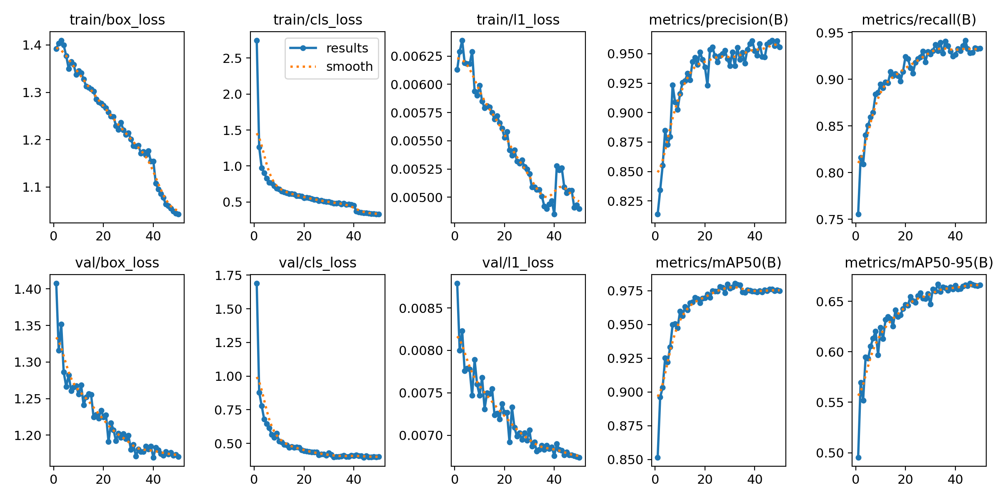

In [2]:
Image('/home/ziba/runs/detect/train/results.png')

## Load the (annotation-corrected) validation dataset and class names in supervision format

In [2]:
ds=sv.DetectionDataset.from_yolo(images_directory_path='/mnt/d/dataset/helmet_dataset/valid/images',
                                 annotations_directory_path='/mnt/d/dataset/helmet_dataset/valid/labels',
                                 data_yaml_path='/mnt/d/dataset/helmet_dataset/data.yaml')
class_names=ds.classes

## predict validation 

## Run inference on the corrected validation set and compute mAP against the fixed ground truth

In [3]:
# load best model
best_model=YOLO('/home/ziba/runs/detect/train/weights/best.pt')

predictions=[]
labels=[]
img_pathes=[]

for img_path , img , label in ds:
    predict=best_model.predict(img, imgsz=640 , conf=.25, iou=.5, device=0, save=False, verbose=False)[0]
    detection=sv.Detections.from_ultralytics(predict).with_nms()
    predictions.append(detection)
    labels.append(label)
    img_pathes.append(img_path)

mAP=MeanAveragePrecision().update(predictions , labels).compute()

## Evaluate the YOLO model on the validation set and print precision, recall, mAP50, and mAP50-95.

In [4]:
base_model_path='/home/ziba/runs/detect/train/weights/best.pt'

r=YOLO(base_model_path).val(data='/mnt/d/dataset/helmet_dataset/data.yaml', split="val", imgsz=640, plots=False)

print('base model', f"P={r.box.mp:.3f} R={r.box.mr:.3f} mAP50={r.box.map50:.3f} mAP50-95={r.box.map:.3f}")

Ultralytics 8.4.138 🚀 Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
YOLO26n summary (fused): 122 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.4±0.1 ms, read: 4.4±2.0 MB/s, size: 30.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /mnt/d/dataset/helmet_dataset/valid/labels.cache... 1054 images, 95 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1054/1054 245.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 66/66 11.8it/s 5.6s0.1s
                   all       1054       3008      0.962      0.925      0.973      0.649
Speed: 0.4ms preprocess, 3.3ms inference, 0.0ms loss, 0.1ms postprocess per image
base model P=0.962 R=0.925 mAP50=0.973 mAP50-95=0.649


In [4]:
print(f'mAP50 : {mAP.map50:.2f}')
print(f'mAP50-90 : {mAP.map50_95:.2f}')
print(f'mAP75 : {mAP.map75:.2f}')

mAP50 : 0.95
mAP50-90 : 0.65
mAP75 : 0.78


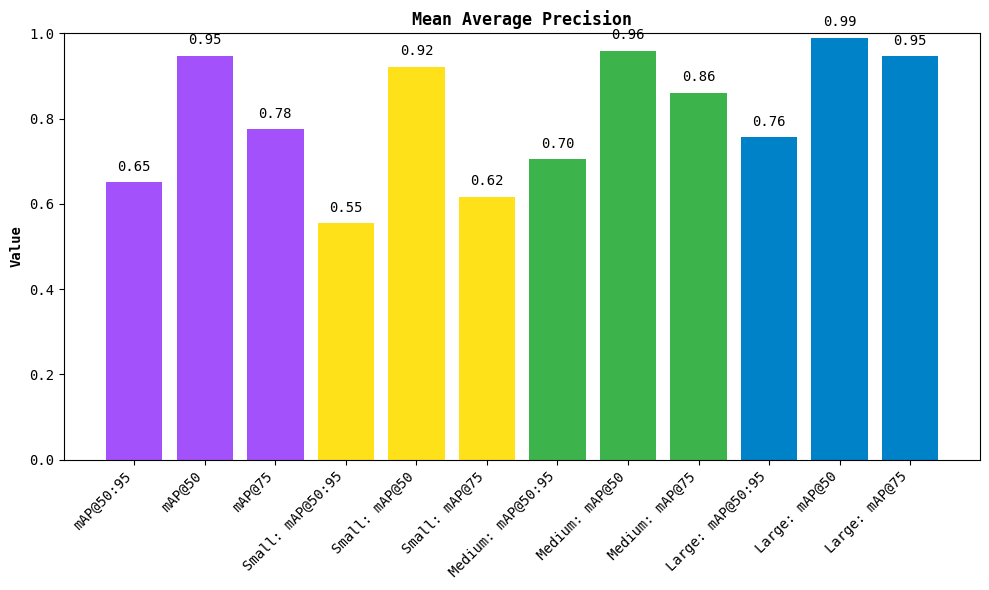

In [6]:
mAP.plot()

## Compute confusion matrix and derive overall precision/recall at IoU=0.3

In [4]:
confusion_matrix = sv.ConfusionMatrix.from_detections( predictions=predictions, targets=labels,
                                                       classes=class_names, conf_threshold=0.25, iou_threshold=0.3)

total_tp = confusion_matrix.matrix[0, 0]
total_fn = confusion_matrix.matrix[0, 1]
total_fp = confusion_matrix.matrix[1, 0]

precision = total_tp / (total_tp + total_fp)
recall = total_tp / (total_tp + total_fn)

print(f"TP: {total_tp}, FP: {total_fp}, FN: {total_fn}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")

TP: 2858, FP: 91, FN: 150
Precision: 0.9691
Recall:    0.9501


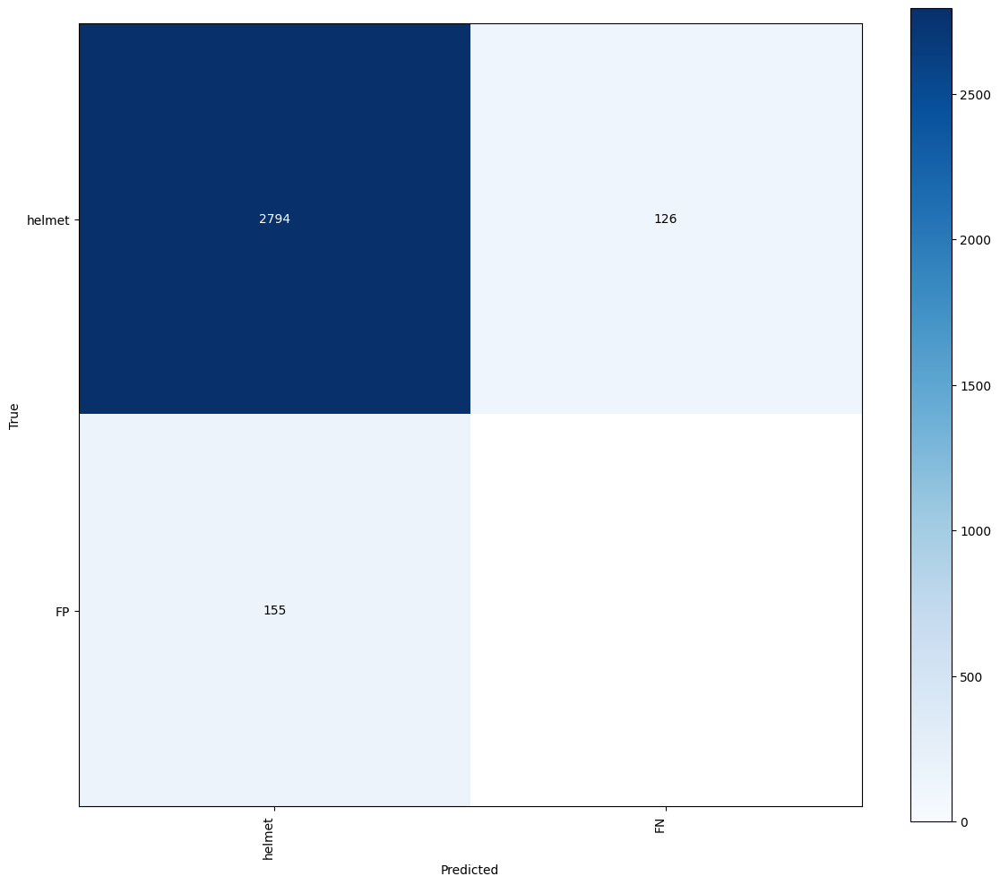

In [8]:
confusion_matrix.plot();

## Compute per-image TP/FP/FN and collect images that still have errors

In [14]:
image_names = [Path(p).name for p in img_pathes]
error_images = {}

for name, pred_det, gt_det in zip(image_names, predictions, labels):
    cm = sv.ConfusionMatrix.from_detections(predictions=[pred_det], targets=[gt_det],        
                                            classes=['helmet'], conf_threshold=0.25, iou_threshold=0.3,)
    tp = cm.matrix[0, 0]
    fn = cm.matrix[0, 1]
    fp = cm.matrix[1, 0]

    if fp > 0 or fn > 0:
        error_images[name] = {"TP": int(tp), "FP": int(fp), "FN": int(fn)}

print(f"Images with errors: {len(error_images)}")

Images with errors: 192


## Sort error images by total error count and print the 20 worst cases

In [11]:
sorted_errors = sorted(error_images.items(),
                       key=lambda x: x[1]["FP"] + x[1]["FN"], reverse=True)

for image_name, result in sorted_errors[:20]:
    print(image_name, "TP:", result["TP"], "FP:", result["FP"], "FN:", result["FN"] )

000052_jpg.rf.629cc4e04ec1578c1e813c84be098fd0.jpg TP: 7 FP: 3 FN: 1
002774_jpg.rf.294b3c1de09560e7791458885ebf1ef9.jpg TP: 3 FP: 0 FN: 4
003107_jpg.rf.46644fdec9d5b9060c4669db880d0044.jpg TP: 12 FP: 0 FN: 4
003837_jpg.rf.7d20ea96c1eb0b9f2e3c63db0f3f1acf.jpg TP: 5 FP: 0 FN: 4
000691_jpg.rf.a2e9ed65a1b11d68c5534bd753e8acab.jpg TP: 10 FP: 2 FN: 1
001426_jpg.rf.8f504ea31e48c4a0c4e348bbd9ff557f.jpg TP: 4 FP: 0 FN: 3
001821_jpg.rf.e646f0d6c39b04efbca423e4afed3fc6.jpg TP: 12 FP: 2 FN: 1
002465_jpg.rf.00b1704fb0c92d32f9b782ae874046a1.jpg TP: 1 FP: 3 FN: 0
002986_jpg.rf.15bdae134dea448596850dd262abf391.jpg TP: 9 FP: 0 FN: 3
003736_jpg.rf.4bc68ed0642177a8d90aff7eb3408687.jpg TP: 3 FP: 0 FN: 3
003804_jpg.rf.5e1b09e6c3b8ea5e98714917ea21104a.jpg TP: 4 FP: 2 FN: 1
003910_jpg.rf.7ea228aecbb2002cbcf592ecd559125a.jpg TP: 0 FP: 0 FN: 3
004449_jpg.rf.691b357eb4510270814bf884b9474177.jpg TP: 6 FP: 0 FN: 3
004765_jpg.rf.a2023e0f74a795034b0647b43d2969d3.jpg TP: 2 FP: 2 FN: 1
000064_jpg.rf.a92f46d2aa832e256

## Greedily match GT-prediction pairs per image and compute the mean IoU over true positives

In [5]:
def tp_ious_for_image(pred_xyxy, gt_xyxy, iou_threshold=0.3):
    
    if len(pred_xyxy) == 0 or len(gt_xyxy) == 0:
        return []

    iou_matrix = box_iou(gt_xyxy, pred_xyxy).clone()
    ious = []

    for _ in range(min(iou_matrix.shape)):
        best_iou, idx = iou_matrix.max(), iou_matrix.argmax()
        if best_iou < iou_threshold:
            break
        gt_idx, pred_idx = divmod(idx.item(), iou_matrix.shape[1])
        ious.append(best_iou.item())
        iou_matrix[gt_idx, :] = -1
        iou_matrix[:, pred_idx] = -1

    return ious

tp_ious = [iou for pred_det, gt_det in zip(predictions, labels)
           for iou in tp_ious_for_image(torch.tensor(pred_det.xyxy, dtype=torch.float32),
                                        torch.tensor(gt_det.xyxy, dtype=torch.float32),)]

mean_tp_iou = sum(tp_ious) / len(tp_ious)
print(f"Mean IoU over TPs: {mean_tp_iou:.4f}")

Mean IoU over TPs: 0.8330


## Split error images into those containing FPs and those containing FNs

In [14]:
fp_images = {}
fn_images = {}

for image_name, result in error_images.items():

    if result["FP"] > 0:
        fp_images[image_name] = result["FP"]

    if result["FN"] > 0:
        fn_images[image_name] = result["FN"]

print("Images with FP:", len(fp_images))
print("Images with FN:", len(fn_images))

Images with FP: 90
Images with FN: 115


## Print the 20 images with the highest number of false negatives

In [15]:
sorted_fn = sorted(fn_images.items(),
                   key=lambda x: x[1],reverse=True)

for image_name, fn in sorted_fn[:20]:
    print(image_name, "FN:", fn)

002774_jpg.rf.294b3c1de09560e7791458885ebf1ef9.jpg FN: 4
003107_jpg.rf.46644fdec9d5b9060c4669db880d0044.jpg FN: 4
003837_jpg.rf.7d20ea96c1eb0b9f2e3c63db0f3f1acf.jpg FN: 4
001426_jpg.rf.8f504ea31e48c4a0c4e348bbd9ff557f.jpg FN: 3
002986_jpg.rf.15bdae134dea448596850dd262abf391.jpg FN: 3
003736_jpg.rf.4bc68ed0642177a8d90aff7eb3408687.jpg FN: 3
003910_jpg.rf.7ea228aecbb2002cbcf592ecd559125a.jpg FN: 3
004449_jpg.rf.691b357eb4510270814bf884b9474177.jpg FN: 3
000156_jpg.rf.5d1aeed2f69a57b2adad91c173d6336f.jpg FN: 2
000793_jpg.rf.e8afa2640bb45ee11ef3ce1ba3757c81.jpg FN: 2
001349_jpg.rf.a17a6d04e4c87399fa1a396afce46859.jpg FN: 2
001425_jpg.rf.85d7c982df869a1abb42dc3144e9f9ec.jpg FN: 2
001490_jpg.rf.a7b09ec72af2e4db2a629c00b9f4fb59.jpg FN: 2
002977_jpg.rf.a166f26a5ead3f666e6c820f391f1879.jpg FN: 2
003058_jpg.rf.630b00062f0c9a4bb5c2687c32ea7024.jpg FN: 2
003960_jpg.rf.1d5ca7f744183cd314fa162eec7cf80c.jpg FN: 2
004322_jpg.rf.9e587b6e056699ccfcb3ef110a22d9b0.jpg FN: 2
005096_jpg.rf.b173d6c58ec567d12

## Print the 20 images with the highest number of false posetive

In [16]:
sorted_fp = sorted(fp_images.items(),
                   key=lambda x: x[1],reverse=True)

for image_name, fp in sorted_fp[:20]:
    print(image_name, "FP:", fp)

000052_jpg.rf.629cc4e04ec1578c1e813c84be098fd0.jpg FP: 3
002465_jpg.rf.00b1704fb0c92d32f9b782ae874046a1.jpg FP: 3
000691_jpg.rf.a2e9ed65a1b11d68c5534bd753e8acab.jpg FP: 2
000729_jpg.rf.3dc63b173121a5b86fbe6cb8f5e7638e.jpg FP: 2
000769_jpg.rf.5cc8c53615e3e64ca0f91594dc6b23bd.jpg FP: 2
001426_jpg.rf.8f504ea31e48c4a0c4e348bbd9ff557f.jpg FP: 2
001761_jpg.rf.e8b2d1e1d3cc37ac51863ce647d4f932.jpg FP: 2
001821_jpg.rf.e646f0d6c39b04efbca423e4afed3fc6.jpg FP: 2
002263_jpg.rf.58e1fa1c560708da0ca082941682983c.jpg FP: 2
002550_jpg.rf.fabcbac31ffa132c757290679a2b1146.jpg FP: 2
003378_jpg.rf.f1e262c8efa2842ae592067a2a29ab6f.jpg FP: 2
003804_jpg.rf.5e1b09e6c3b8ea5e98714917ea21104a.jpg FP: 2
004765_jpg.rf.a2023e0f74a795034b0647b43d2969d3.jpg FP: 2
004999_jpg.rf.0e0a808127813375d14a4da6e8b2c30c.jpg FP: 2
000047_jpg.rf.d9ec04956826049598e2e2ba03a8a25d.jpg FP: 1
000064_jpg.rf.a92f46d2aa832e256d736354ff5567ab.jpg FP: 1
000071_jpg.rf.e7e7d362394e009bc299436f052c41f6.jpg FP: 1
000273_jpg.rf.369643031185175d6

## Define image directory and helper to find matched GT/prediction indices via greedy IoU matching

In [6]:
images_dir = Path('/mnt/d/dataset/helmet_dataset/valid/images')

def matched_indices(gt_xyxy, pred_xyxy, iou_threshold=0.3):
    """برمی‌گردونه: اندیس‌های GT و prediction که match شدن"""
    matched_gt, matched_pred = set(), set()
    if len(gt_xyxy) and len(pred_xyxy):
        iou_matrix = box_iou(gt_xyxy, pred_xyxy).clone()
        
        for _ in range(min(iou_matrix.shape)):
            best_iou, idx = iou_matrix.max(), iou_matrix.argmax()
            
            if best_iou < iou_threshold:
                break
            
            gt_idx, pred_idx = divmod(idx.item(), iou_matrix.shape[1])
            matched_gt.add(gt_idx)
            matched_pred.add(pred_idx)
            iou_matrix[gt_idx, :] = -1
            iou_matrix[:, pred_idx] = -1
   
    return matched_gt, matched_pred

## Annotate an image with TP predictions (green), FP predictions (red), and FN ground truths (yellow)

In [7]:
def draw_errors(image, pred_det, gt_det, iou_threshold=0.3):
    matched_gt, matched_pred = matched_indices(torch.tensor(gt_det.xyxy, dtype=torch.float32),
                                               torch.tensor(pred_det.xyxy, dtype=torch.float32), iou_threshold)
    
    tp_mask = np.isin(np.arange(len(pred_det)), list(matched_pred))
    fn_mask = ~np.isin(np.arange(len(gt_det)), list(matched_gt))

    image = sv.BoxAnnotator(color=sv.Color.GREEN, thickness=1).annotate(image.copy(), pred_det[tp_mask])
    image = sv.BoxAnnotator(color=sv.Color.RED, thickness=1).annotate(image, pred_det[~tp_mask])
    image = sv.BoxAnnotator(color=sv.Color.YELLOW, thickness=1).annotate(image, gt_det[fn_mask])
    return image

## Visualize the 20 worst error images in a 2x2 grid, annotated with TP/FP/FN boxes

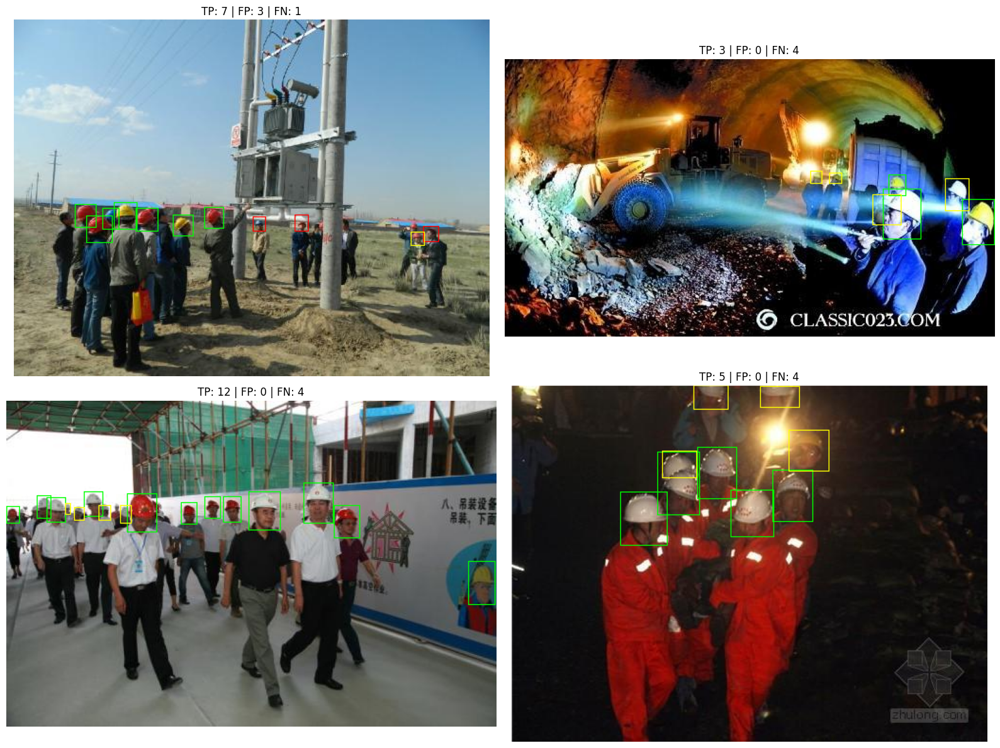

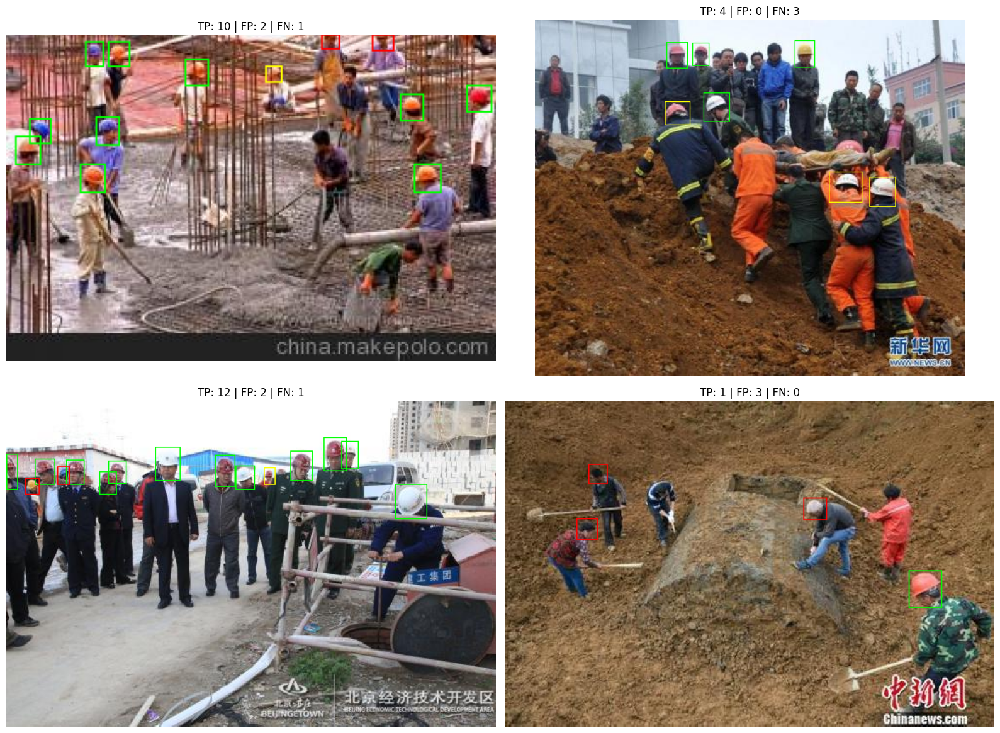

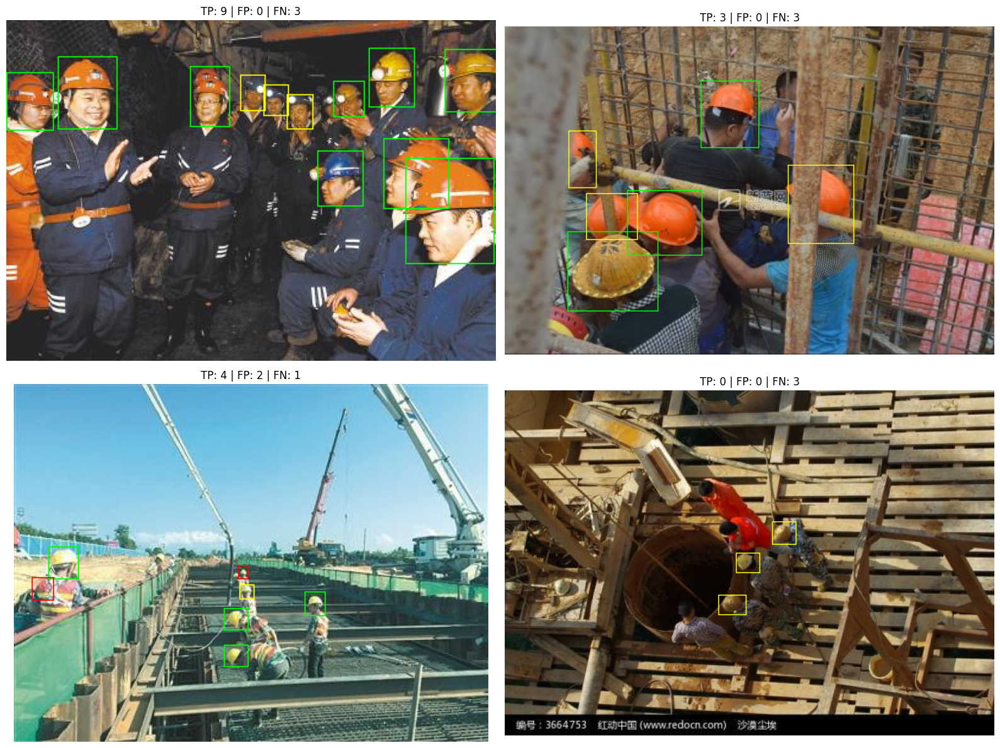

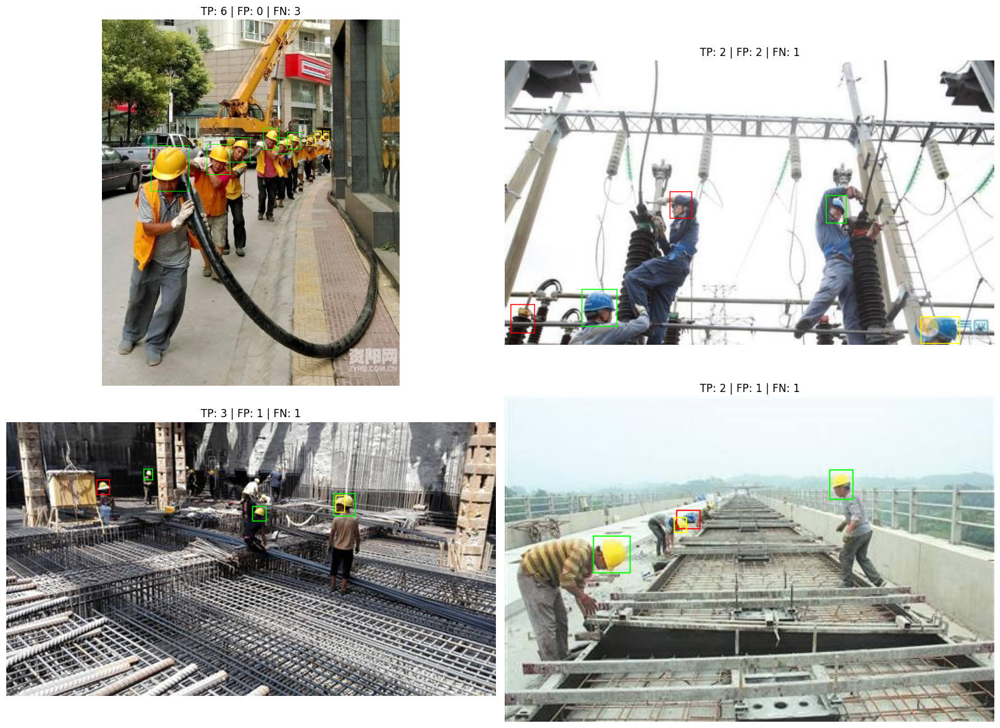

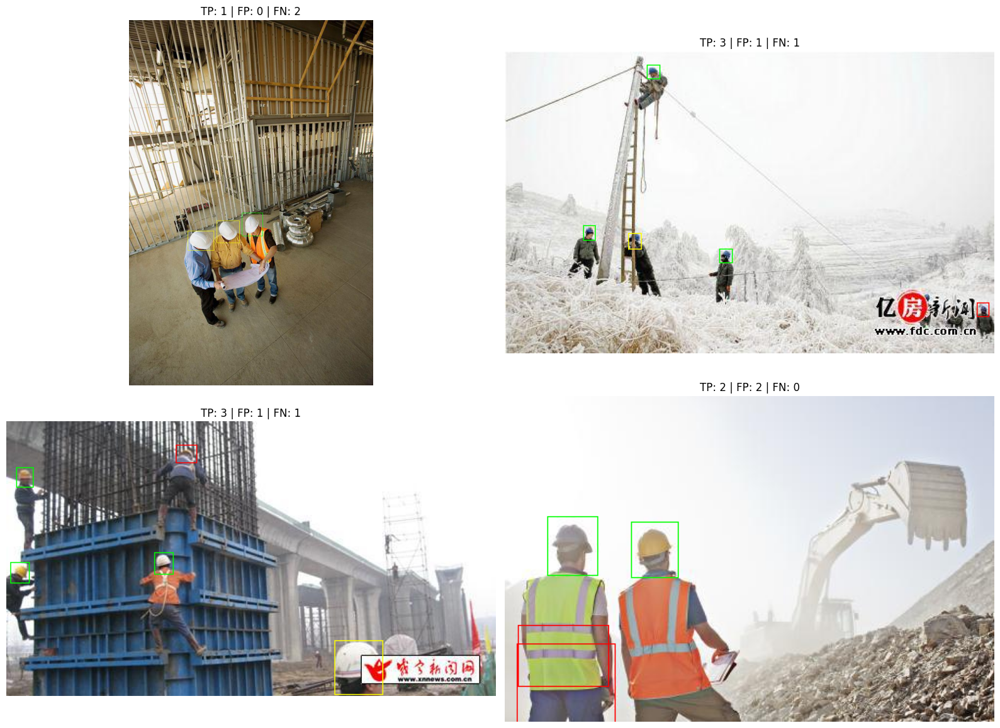

In [12]:
selected_errors = sorted_errors[:20]

for start in range(0, len(selected_errors), 4):
    batch = selected_errors[start:start + 4]
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    for ax, (image_name, result) in zip(axes.flat, batch):
        idx = image_names.index(image_name)

        image_bgr = cv.imread(str(images_dir / image_name))            # خام، هنوز BGR
        annotated_bgr = draw_errors(image_bgr, predictions[idx], labels[idx])  # annotate روی BGR
        annotated_rgb = cv.cvtColor(annotated_bgr, cv.COLOR_BGR2RGB)    # تبدیل فقط برای نمایش

        ax.imshow(annotated_rgb)
        ax.set_title(f"TP: {result['TP']} | FP: {result['FP']} | FN: {result['FN']}")
        ax.axis('off')

    for ax in axes.flat[len(batch):]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Most FN errors occurred in challenging visual conditions such as strong illumination, reflections, partial visibility, and crowded scenes.

# Most FP errors were associated with visually similar non-helmet objects or incomplete ground-truth annotations, especially near image boundaries.

In [15]:
"""
Create assets/dataset_samples.png: a grid of training images with helmet boxes
(from sparse to crowded scenes) plus one background image (no helmet boxes).

Usage (from a notebook or terminal):
    python make_dataset_samples.py /path/to/helmet_dataset assets/dataset_samples.png
"""

IMG_EXTS = {".jpg", ".jpeg", ".png"}
SEED = 42
N_HELMET_IMAGES = 5          # + 1 background image = 6 panels (2 x 3)
BOX_COLOR = (0, 200, 0)      # RGB green
BOX_THICKNESS = 2


def read_boxes(label_path: Path, w: int, h: int) -> list[tuple[int, int, int, int]]:
    """YOLO label file -> list of pixel xyxy boxes (empty list if no boxes / missing file)."""
    if not label_path.exists():
        return []
    boxes = []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        _, xc, yc, bw, bh = map(float, parts)
        x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
        x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
        boxes.append((x1, y1, x2, y2))
    return boxes


def main(data_path: str, out_path: str, split: str = "train") -> None:
    data_path, out_path = Path(data_path), Path(out_path)
    images_dir = data_path / split / "images"
    labels_dir = data_path / split / "labels"

    # Count boxes per image from the label files only (fast, no image decoding)
    counts = {}
    for img in sorted(images_dir.iterdir()):
        if img.suffix.lower() in IMG_EXTS:
            label = labels_dir / f"{img.stem}.txt"
            n = len([l for l in label.read_text().splitlines() if l.strip()]) if label.exists() else 0
            counts[img] = n

    with_helmets = [p for p, n in counts.items() if n > 0]
    backgrounds = [p for p, n in counts.items() if n == 0]
    if not with_helmets or not backgrounds:
        raise RuntimeError(f"Need both helmet and background images (got {len(with_helmets)} / {len(backgrounds)}).")

    # Pick images spread from few to many helmets (shuffle first so ties are random but reproducible)
    rng = random.Random(SEED)
    rng.shuffle(with_helmets)
    with_helmets.sort(key=lambda p: counts[p])
    # skip the extreme tail (e.g. 30+ helmets) so the figure stays readable
    idx = np.linspace(0, int(len(with_helmets) * 0.97), N_HELMET_IMAGES).round().astype(int)
    chosen = [with_helmets[i] for i in idx] + [rng.choice(backgrounds)]

    n_panels = len(chosen)
    cols = 3
    rows = int(np.ceil(n_panels / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, img_path in zip(axes, chosen):
        img = cv.cvtColor(cv.imread(str(img_path)), cv.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        boxes = read_boxes(labels_dir / f"{img_path.stem}.txt", w, h)
        for x1, y1, x2, y2 in boxes:
            cv.rectangle(img, (x1, y1), (x2, y2), BOX_COLOR, BOX_THICKNESS)
        ax.imshow(img)
        ax.set_title(f"{len(boxes)} helmet{'s' if len(boxes) != 1 else ''}" if boxes else "background (no helmet)", fontsize=12)
        ax.axis("off")

    for ax in axes[n_panels:]:
        ax.axis("off")

    fig.suptitle("Training samples: helmet boxes (green) and a background image", fontsize=14)
    fig.tight_layout()
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    print("Saved:", out_path.resolve())
    for p in chosen:
        print(f"  {p.name}  ({counts[p]} boxes)")



main("/mnt/d/dataset/helmet_dataset", "assets/dataset_samples.png")

Saved: /home/ziba/pythonProject/DeepLearning/PYtorch/yolo26/helmet_detection/assets/dataset_samples.png
  000264_jpg.rf.ce0a76b59f6a190a8fe6c821b6f10266.jpg  (1 boxes)
  003396_jpg.rf.d527962d54ecbe63b5ad0b647283a537.jpg  (1 boxes)
  002297_jpg.rf.1554f92b398cc7617ff575fc2fe4e07b.jpg  (2 boxes)
  002683_jpg.rf.4d31de2efc0b55fd930419b5249d57e5.jpg  (4 boxes)
  000816_jpg.rf.5a5105db9b5b68ed7deff7d298d62c51.jpg  (10 boxes)
  004899_jpg.rf.6ecbffb4c82097454d44d64d8ed32168.jpg  (0 boxes)


# _______________________________________________________________________________________________________

## Load dataset into FiftyOne, run inference, and evaluate detections / compute mistakenness for error analysis

In [8]:
dataset = fo.Dataset.from_dir(dataset_type=fo.types.YOLOv5Dataset,
                              yaml_path='/mnt/d/dataset/helmet_dataset/data.yaml', split='val')

dataset.apply_model(best_model, label_field="predictions")

results = dataset.evaluate_detections("predictions", gt_field="ground_truth", eval_key="eval", iou=0.3)


fob.compute_mistakenness(dataset, "predictions", label_field="ground_truth")

You are running the oldest supported major version of MongoDB. Please refer to https://deprecation.voxel51.com for deprecation notices. You can suppress this exception by setting your `database_validation` config parameter to `False`. See https://docs.voxel51.com/user_guide/config.html#configuring-a-mongodb-connection for more information
 100% |███████████████| 1054/1054 [3.4s elapsed, 0s remaining, 304.1 samples/s]      
 100% |███████████████| 1054/1054 [15.5s elapsed, 0s remaining, 71.5 samples/s]      
Evaluating detections...
 100% |███████████████| 1054/1054 [3.2s elapsed, 0s remaining, 384.5 samples/s]      
Evaluating detections...
 100% |███████████████| 1054/1054 [3.7s elapsed, 0s remaining, 318.2 samples/s]      
Computing mistakenness...
 100% |███████████████| 1054/1054 [3.1s elapsed, 0s remaining, 371.5 samples/s]      
Mistakenness computation complete


## Launch the FiftyOne App to visually explore the dataset and evaluation results


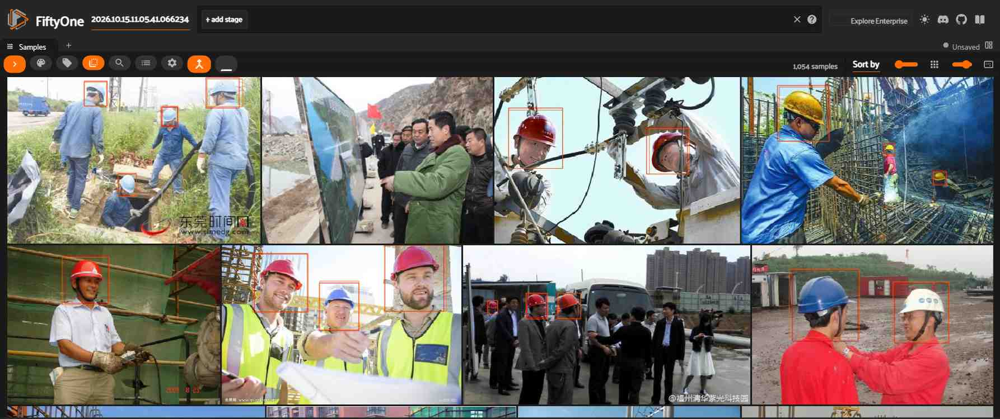

In [10]:
session = fo.launch_app(dataset)

## Filter high-confidence FP predictions (likely missing GT annotations) and show them in the App

In [11]:
suspicious_view = dataset.filter_labels("predictions", (F("eval") == "fp") & (F("confidence") > 0.3), only_matches=True)

print(f"تعداد پیش‌بینی‌های مشکوک به annotation گمشده: {suspicious_view.count('predictions.detections')}")

session.view = suspicious_view

تعداد پیش‌بینی‌های مشکوک به annotation گمشده: 149


## Set CVAT credentials as environment variables for FiftyOne's CVAT backend

In [6]:
os.environ["FIFTYONE_CVAT_USERNAME"] = "z.228hatamian@gmail.com"
os.environ["FIFTYONE_CVAT_PASSWORD"] = "ZibaHassan99"

## Iteratively send unannotated batches to CVAT, wait for manual annotation, then merge results back

In [41]:
batch_size = 20
used_keys = []
remaining = suspicious_view

batch_num = 1
while len(remaining) > 0:
    anno_key = f"fix_missing_helmets_{batch_num}"
    next_batch = remaining.take(batch_size)

    print(f"\n=== Batch {batch_num}: {len(next_batch)} عکس ===")
    next_batch.annotate( anno_key, label_field="ground_truth", label_type="detections",
                         classes=["helmet"], launch_editor=True, image_quality=50, chunk_size=10)

    input(f"\nبعد از اتمام annotate کردن و Completed کردن Job در CVAT برای batch {batch_num}، اینجا Enter بزن تا ادامه بدیم...")

    dataset.load_annotations(anno_key)
    used_keys.append(anno_key)

    done_ids = []
    for key in used_keys:
        done_ids += dataset.load_annotation_view(key).values("id")

    remaining = suspicious_view.exclude(done_ids)
    print(f"باقی‌مونده: {len(remaining)}")

    batch_num += 1

print("\n✅ همه‌ی عکس‌های مشکوک annotate شدن!")


=== Batch 1: 20 عکس ===
Please enter your login credentials.
You can avoid this in the future by setting your `FIFTYONE_CVAT_USERNAME` and `FIFTYONE_CVAT_PASSWORD` environment variables


Username:  z.228hatamian@gmail.com
Password:  ········


Uploading samples to CVAT...
Launching editor at 'https://app.cvat.ai/tasks/2642033/jobs/4541855'...



بعد از اتمام annotate کردن و Completed کردن Job در CVAT برای batch 1، اینجا Enter بزن تا ادامه بدیم... 


Download complete
Loading labels for field 'ground_truth'...
 100% |███████████████████| 19/19 [64.6ms elapsed, 0s remaining, 293.9 samples/s] 
باقی‌مونده: 152

=== Batch 2: 20 عکس ===
Please enter your login credentials.
You can avoid this in the future by setting your `FIFTYONE_CVAT_USERNAME` and `FIFTYONE_CVAT_PASSWORD` environment variables


...

Download complete
Loading labels for field 'ground_truth'...
 100% |███████████████████| 20/20 [58.9ms elapsed, 0s remaining, 339.3 samples/s] 
باقی‌مونده: 12

=== Batch 9: 12 عکس ===
Please enter your login credentials.
You can avoid this in the future by setting your `FIFTYONE_CVAT_USERNAME` and `FIFTYONE_CVAT_PASSWORD` environment variables


Username:  z.228hatamian@gmail.com
Password:  ········


Uploading samples to CVAT...
Launching editor at 'https://app.cvat.ai/tasks/2642057/jobs/4541877'...



بعد از اتمام annotate کردن و Completed کردن Job در CVAT برای batch 9، اینجا Enter بزن تا ادامه بدیم... 


Download complete
Loading labels for field 'ground_truth'...
 100% |███████████████████| 12/12 [41.8ms elapsed, 0s remaining, 287.4 samples/s] 
باقی‌مونده: 0

✅ همه‌ی عکس‌های مشکوک annotate شدن!


## List all FiftyOne datasets currently stored to locate the one with the corrected annotations

In [18]:
print(fo.list_datasets())

['2026.10.02.16.09.28.499964', '2026.10.02.16.13.44.361597', '2026.10.02.16.16.32.387748', '2026.10.03.18.36.47.348911', '2026.10.03.18.51.51.520331', '2026.10.03.22.06.46.449278', '2026.10.03.22.12.12.875486', '2026.10.03.22.18.48.576465', '2026.10.03.22.24.21.502728', '2026.10.04.09.26.50.287588']


## Inspect each dataset's sample/GT-box counts to identify the one with corrected annotations

In [3]:
for name in fo.list_datasets():
    ds = fo.load_dataset(name)
    if "ground_truth" in ds.get_field_schema():
        n_gt = ds.count("ground_truth.detections")
        print(f"{name}: {len(ds)} samples, {n_gt} GT boxes")
    else:
        print(f"{name}: {len(ds)} samples, فیلد ground_truth نداره")

2026.10.02.16.09.28.499964: 0 samples, فیلد ground_truth نداره
2026.10.02.16.13.44.361597: 1054 samples, 2920 GT boxes
2026.10.02.16.16.32.387748: 1054 samples, 2920 GT boxes
2026.10.03.18.36.47.348911: 1054 samples, 2920 GT boxes
2026.10.03.18.51.51.520331: 1054 samples, 2920 GT boxes
2026.10.03.22.06.46.449278: 1054 samples, 2920 GT boxes
2026.10.03.22.12.12.875486: 1054 samples, 2920 GT boxes
2026.10.03.22.18.48.576465: 1054 samples, 2920 GT boxes
2026.10.03.22.24.21.502728: 1054 samples, 2988 GT boxes


## Load the identified dataset and export its corrected ground_truth labels in YOLOv5 format

In [ ]:
dataset = fo.load_dataset("2026.10.03.22.24.21.502728")

dataset.export( export_dir="/mnt/d/dataset/helmet_dataset/valid_fixed",
                dataset_type=fo.types.YOLOv5Dataset, label_field="ground_truth")

## Verify the exported labels folder contains the expected number of annotation files

In [7]:
labels_dir = "/mnt/d/dataset/helmet_dataset/valid_fixed/labels/val"
files = os.listdir(labels_dir)
print(f"تعداد فایل‌های .txt: {len(files)}")
print(files[:5])

تعداد فایل‌های .txt: 1054
['000003_jpg.rf.9fc4dfe06775f585757ede9300ba6af9.txt', '000004_jpg.rf.6e499d6a5b40d901d318a92e672842ce.txt', '000005_jpg.rf.2459a55dca0ff3afbe13f8d219a9a818.txt', '000012_jpg.rf.2e49c7cac1f974388e32964f138453ca.txt', '000016_jpg.rf.80946bcc8f5f0a9f13c94fce3439dfad.txt']


## Compare the original vs. exported label file for one sample to confirm the fix was applied

In [14]:
# یکی از sample های suspicious_view رو بردارید
sample = suspicious_view.first()
image_name = os.path.basename(sample.filepath)
txt_name = os.path.splitext(image_name)[0] + ".txt"

old_path = f"/mnt/d/dataset/helmet_dataset/valid/labels/000769_jpg.rf.5cc8c53615e3e64ca0f91594dc6b23bd.txt"
new_path = f"/mnt/d/dataset/helmet_dataset/valid_fixed/labels/val/000769_jpg.rf.5cc8c53615e3e64ca0f91594dc6b23bd.txt"

print("--- فایل قدیمی ---")
with open(old_path) as f:
    print(f.read())

print("--- فایل جدید (export شده) ---")
with open(new_path) as f:
    print(f.read())

--- فایل قدیمی ---
0 0.416 0.403030303030303 0.084 0.1393939393939394
0 0.614 0.38484848484848483 0.072 0.10909090909090909
0 0.734 0.03333333333333333 0.056 0.06060606060606061
0 0.391 0.12424242424242424 0.042 0.07272727272727272
0 0.769 0.051515151515151514 0.042 0.07272727272727272
0 0.817 0.05606060606060606 0.026 0.051515151515151514
0 0.871 0.03787878787878788 0.026 0.045454545454545456
0 0.889 0.05454545454545454 0.026 0.04242424242424243
--- فایل جدید (export شده) ---
0 0.416000 0.403030 0.084000 0.139394
0 0.614000 0.384848 0.072000 0.109091
0 0.734000 0.033333 0.056000 0.060606
0 0.391000 0.124242 0.042000 0.072727
0 0.769000 0.051515 0.042000 0.072727
0 0.817000 0.056061 0.026000 0.051515
0 0.871000 0.037879 0.026000 0.045455
0 0.889000 0.054545 0.026000 0.042424
0 0.352000 0.107576 0.024000 0.039394
0 0.198000 0.195455 0.020000 0.033333


## Back up the original labels folder before overwriting with corrected annotations

In [15]:
cp -r /mnt/d/dataset/helmet_dataset/valid/labels /mnt/d/dataset/helmet_dataset/valid/labels_backup_$(date +%Y%m%d)

## Overwrite the original labels with the corrected, exported annotations

In [16]:
cp -r /mnt/d/dataset/helmet_dataset/valid_fixed/labels/val/* /mnt/d/dataset/helmet_dataset/valid/labels/

## Confirm the final file count in the original labels folder after replacement

In [17]:
old_count = len(os.listdir("/mnt/d/dataset/helmet_dataset/valid/labels"))
print(f"تعداد فایل‌های نهایی در پوشه‌ی اصلی: {old_count}")

تعداد فایل‌های نهایی در پوشه‌ی اصلی: 1054


In [ ]:
image_name =['001821_jpg.rf.e646f0d6c39b04efbca423e4afed3fc6.jpg', '000064_jpg.rf.a92f46d2aa832e256d736354ff5567ab.jpg',
             '002550_jpg.rf.fabcbac31ffa132c757290679a2b1146.jpg','004792_jpg.rf.752ad93015391618d903b05a7ae7503d.jpg', 
             '000052_jpg.rf.629cc4e04ec1578c1e813c84be098fd0.jpg', '002263_jpg.rf.58e1fa1c560708da0ca082941682983c.jpg',
             '000690_jpg.rf.e40f4021338a604f5243efffebf708df.jpg','000691_jpg.rf.a2e9ed65a1b11d68c5534bd753e8acab.jpg']

anno_key = "fix_helm"


view = dataset.match(fo.ViewField("filepath").ends_with(tuple(image_name)))
print(len(view))
print(view.values("filepath"))

view.annotate(anno_key, label_field="ground_truth", label_type="detections",
              classes=["helmet"], launch_editor=True)

In [10]:
dataset.load_annotations(anno_key, cleanup=True)

for sample in view:
    print(sample.filepath)
    print(sample.ground_truth.detections)

for sample in view:
    print("\n", sample.filepath)
    
    for det in sample.ground_truth.detections:
        print(det.label, det.bounding_box)



 100% |███████████████████████| 0/0 [360.8us elapsed, ? remaining, ? tasks/s] 
Download complete
Loading labels for field 'ground_truth'...
 100% |█████████████████████| 0/0 [1.5ms elapsed, ? remaining, ? samples/s] 
/mnt/d/dataset/helmet_dataset/valid/images/000052_jpg.rf.629cc4e04ec1578c1e813c84be098fd0.jpg
[<Detection: {
    'id': '6ac681088bbc2d546a53a450',
    'attributes': {},
    'tags': [],
    'label': 'helmet',
    'bounding_box': [0.152, 0.5493333333333333, 0.054, 0.07466666666666667],
    'mask': None,
    'mask_path': None,
    'confidence': None,
    'index': None,
    'eval': 'tp',
    'eval_id': '6ac6810d8bbc2d546a53b41a',
    'eval_iou': 0.8469111123027537,
    'mistakenness': 0.08953729271888733,
    'mistakenness_loc': 0.34088640991435104,
    'possible_spurious': None,
}>, <Detection: {
    'id': '6ac681088bbc2d546a53a451',
    'attributes': {},
    'tags': [],
    'label': 'helmet',
    'bounding_box': [0.208, 0.512, 0.05, 0.07466666666666667],
    'mask': None,
  

In [11]:
for sample in view:

    image_path = Path(sample.filepath)

    # YOLO label file
    label_path = image_path.parent.parent / "labels" / f"{image_path.stem}.txt"

    # Create/update label file
    with open(label_path, "w") as f:

        for det in sample.ground_truth.detections:

            # YOLO normalized bbox:
            # [x_center, y_center, width, height]
            x, y, w, h = det.bounding_box

            f.write( f"0 {x + w/2:.6f} {y + h/2:.6f} {w:.6f} {h:.6f}\n")

    print(f"Updated: {label_path}")

Updated: /mnt/d/dataset/helmet_dataset/valid/labels/000052_jpg.rf.629cc4e04ec1578c1e813c84be098fd0.txt
Updated: /mnt/d/dataset/helmet_dataset/valid/labels/000064_jpg.rf.a92f46d2aa832e256d736354ff5567ab.txt
Updated: /mnt/d/dataset/helmet_dataset/valid/labels/000690_jpg.rf.e40f4021338a604f5243efffebf708df.txt
Updated: /mnt/d/dataset/helmet_dataset/valid/labels/000691_jpg.rf.a2e9ed65a1b11d68c5534bd753e8acab.txt
Updated: /mnt/d/dataset/helmet_dataset/valid/labels/001821_jpg.rf.e646f0d6c39b04efbca423e4afed3fc6.txt
Updated: /mnt/d/dataset/helmet_dataset/valid/labels/002263_jpg.rf.58e1fa1c560708da0ca082941682983c.txt
Updated: /mnt/d/dataset/helmet_dataset/valid/labels/002550_jpg.rf.fabcbac31ffa132c757290679a2b1146.txt
Updated: /mnt/d/dataset/helmet_dataset/valid/labels/004792_jpg.rf.752ad93015391618d903b05a7ae7503d.txt


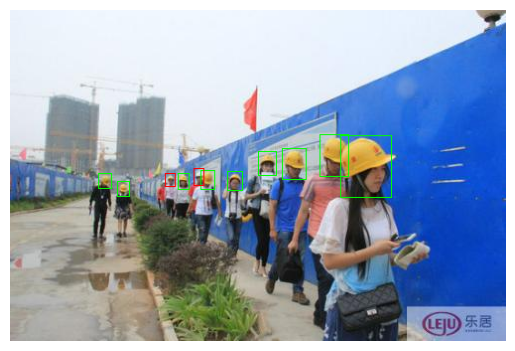

In [19]:
image_name =['001821_jpg.rf.e646f0d6c39b04efbca423e4afed3fc6.jpg', '000064_jpg.rf.a92f46d2aa832e256d736354ff5567ab.jpg',
             '002550_jpg.rf.fabcbac31ffa132c757290679a2b1146.jpg','004792_jpg.rf.752ad93015391618d903b05a7ae7503d.jpg', 
             '000052_jpg.rf.629cc4e04ec1578c1e813c84be098fd0.jpg', '002263_jpg.rf.58e1fa1c560708da0ca082941682983c.jpg',
             '000690_jpg.rf.e40f4021338a604f5243efffebf708df.jpg','000691_jpg.rf.a2e9ed65a1b11d68c5534bd753e8acab.jpg']
images_dir = Path("/mnt/d/dataset/helmet_dataset/valid/images")

sample_name = image_name[5] 
idx = image_names.index(sample_name)

image_bgr = cv.imread(str(images_dir / sample_name))
annotated_bgr = draw_errors(image_bgr, predictions[idx], labels[idx])
annotated_rgb = cv.cvtColor(annotated_bgr, cv.COLOR_BGR2RGB)

plt.imshow(annotated_rgb)
plt.axis('off')
plt.show()

In [20]:
labels_dir = Path("/mnt/d/dataset/helmet_dataset/valid/labels")

for name in image_name:
    label_path = labels_dir / f"{Path(name).stem}.txt"

    print(f"\n{label_path}")
    print(label_path.read_text())


/mnt/d/dataset/helmet_dataset/valid/labels/001821_jpg.rf.e646f0d6c39b04efbca423e4afed3fc6.txt
0 0.333000 0.195195 0.050000 0.078078
0 0.674000 0.162162 0.052000 0.096096
0 0.140000 0.223724 0.040000 0.087087
0 0.210000 0.255255 0.036000 0.072072
0 0.229000 0.220721 0.030000 0.063063
0 0.832000 0.318318 0.064000 0.132132
0 0.701000 0.174174 0.034000 0.090090
0 0.602000 0.198198 0.044000 0.090090
0 0.442000 0.214715 0.044000 0.093093
0 0.487000 0.238739 0.050000 0.087087
0 0.538000 0.231231 0.024000 0.054054
0 0.082000 0.214715 0.044000 0.081081
0 0.013000 0.207207 0.022000 0.084084
0 0.053030 0.260502 0.024537 0.043860
0 0.117293 0.232432 0.022200 0.040351


/mnt/d/dataset/helmet_dataset/valid/labels/000064_jpg.rf.a92f46d2aa832e256d736354ff5567ab.txt
0 0.696000 0.296429 0.028000 0.071429
0 0.518000 0.330357 0.024000 0.053571
0 0.682000 0.300000 0.020000 0.064286
0 0.291000 0.189286 0.018000 0.021429
0 0.199887 0.238519 0.028491 0.043860


/mnt/d/dataset/helmet_dataset/valid/labels/0025